# Multi-armed Bandits: epsilon-greedy vs UCB

Team project, MSc Data Science and AI, University of Liverpool.

It includes:
1. A stationary k-armed bandit environment.
2. Agents using epsilon-greedy and UCB action selection.
3. Experiments for k = 5, 10, 20 with 2000 plays.
4. Figures and a summary table.


## 1. Bandit Environment

We use a stationary k-armed bandit testbed.
    
- The best arm is the one with the highest sampled true value.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Global plotting style used throughout the notebook.
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 120


class Bandit:
    """Stationary k-armed bandit environment."""

    def __init__(self, k):
        self.k = k
        # Sample the underlying true value for each arm.
        self.q_true = np.random.normal(loc=0.0, scale=1.0, size=k)
        self.best_action = int(np.argmax(self.q_true))

    def step(self, action):
        """Return a stochastic reward for the selected action."""
        return np.random.normal(loc=self.q_true[action], scale=1.0)


# 2. Agent and Action Selection

Each agent maintains:

- $Q(a)$: estimated value of each action.
- $N(a)$: number of times each action has been selected.

We compare two exploration strategies:

- **Epsilon-greedy**: with probability $\epsilon$, pick a random arm; otherwise pick $\arg\max_a Q(a)$.
- **UCB (Upper Confidence Bound)**: pick
  $$
  A_t \;=\; \arg\max_a \left[\, Q_t(a) \;+\; c \sqrt{\frac{\ln t}{N_t(a)}} \,\right]
  $$
  where $c>0$ controls the exploration bonus, $t$ is the current time step, and $N_t(a)$ is the number of times arm $a$ has been selected up to time $t$.

UCB balances exploitation (high estimated value) and exploration (high uncertainty bonus for rarely selected arms).

In [ ]:
class Agent:
    """Bandit agent supporting epsilon-greedy or UCB action selection."""

    def __init__(self, k, epsilon=0.1, use_ucb=False, c=2.0):
        self.k = k
        self.epsilon = epsilon
        self.use_ucb = use_ucb
        self.c = c
        self.reset()

    def reset(self):
        """Reset value estimates and counters for a fresh run."""
        self.q_estimates = np.zeros(self.k, dtype=float)
        self.action_counts = np.zeros(self.k, dtype=float)
        self.total_steps = 0

    def act(self):
        """Select an action using the configured strategy."""
        if self.use_ucb:
            # Small constant avoids division by zero before each arm is sampled.
            bonus = self.c * np.sqrt(np.log(self.total_steps + 1.0) / (self.action_counts + 1e-5))
            ucb_values = self.q_estimates + bonus
            return int(np.argmax(ucb_values))

        # Epsilon-greedy action selection.
        if np.random.rand() < self.epsilon:
            return int(np.random.randint(self.k))
        return int(np.argmax(self.q_estimates))

    def learn(self, action, reward):
        """Update action-value estimate via incremental sample-average."""
        self.action_counts[action] += 1
        step_size = 1.0 / self.action_counts[action]
        self.q_estimates[action] += step_size * (reward - self.q_estimates[action])
        self.total_steps += 1


## 3. Simulation Design

For each experiment:

- We sample a new bandit instance per run.
- We evaluate epsilon-greedy agents and a UCB agent.
- We run **2000 runs** and **2000 plays** per run.

Outputs include:

- Mean reward per play.
- Mean percentage of optimal-action selections per play.
- Summary means for the last 500 plays and the final play.


In [ ]:
def simulate(k, runs=2000, steps=2000, epsilons=[0, 0.01, 0.1], use_ucb=True):
    """Run repeated bandit experiments and return aggregated mean."""
    strategy_order = [f"epsilon={epsilon}" for epsilon in epsilons]
    if use_ucb:
        strategy_order.append("UCB")

    # Per play accumulators (summed over runs, then divided by runs).
    reward_sum = {name: np.zeros(steps, dtype=float) for name in strategy_order}
    optimal_sum = {name: np.zeros(steps, dtype=float) for name in strategy_order}

    # Scalar summary accumulators for report table.
    summary_sum = {
        name: {
            "reward_last500_sum": 0.0,
            "reward_final_sum": 0.0,
            "optimal_last500_sum": 0.0,
            "optimal_final_sum": 0.0,
        }
        for name in strategy_order
    }

    tail_window = min(500, steps)

    for _ in range(runs):
        bandit = Bandit(k)

        # Build one agent per strategy for this run.
        agents = {f"epsilon={epsilon}": Agent(k, epsilon=epsilon) for epsilon in epsilons}
        if use_ucb:
            agents["UCB"] = Agent(k, use_ucb=True)

        # Store this run's trajectories before adding to global sums.
        run_rewards = {name: np.zeros(steps, dtype=float) for name in strategy_order}
        run_optimal = {name: np.zeros(steps, dtype=float) for name in strategy_order}

        for step in range(steps):
            for name, agent in agents.items():
                action = agent.act()
                reward = bandit.step(action)
                agent.learn(action, reward)

                run_rewards[name][step] = reward
                run_optimal[name][step] = 1.0 if action == bandit.best_action else 0.0

        # Aggregate run trajectories and scalar summaries.
        for name in strategy_order:
            rewards = run_rewards[name]
            optimal = run_optimal[name]

            reward_sum[name] += rewards
            optimal_sum[name] += optimal

            summary_sum[name]["reward_last500_sum"] += float(np.mean(rewards[-tail_window:]))
            summary_sum[name]["reward_final_sum"] += float(rewards[-1])
            summary_sum[name]["optimal_last500_sum"] += float(np.mean(optimal[-tail_window:]) * 100.0)
            summary_sum[name]["optimal_final_sum"] += float(optimal[-1] * 100.0)

    # Final averaged outputs.
    per_step_stats = {}
    summary_stats = {}

    for name in strategy_order:
        per_step_stats[name] = {
            "reward_mean": reward_sum[name] / runs,
            "optimal_mean": (optimal_sum[name] / runs) * 100.0,
        }

        summary_stats[name] = {
            "reward_last500_mean": summary_sum[name]["reward_last500_sum"] / runs,
            "reward_final_mean": summary_sum[name]["reward_final_sum"] / runs,
            "optimal_last500_mean": summary_sum[name]["optimal_last500_sum"] / runs,
            "optimal_final_mean": summary_sum[name]["optimal_final_sum"] / runs,
        }

    return per_step_stats, summary_stats


## 4. Visualisation Layout

Results are shown in a 3 x 2 grid:

- Rows correspond to \(k = 5, 10, 20\).
- Left column: average reward over plays.
- Right column: percentage of optimal actions over plays.

The color palette is high-contrast, and labels are formatted in black for report readability.


In [ ]:
def plot_results_grid(results_by_k, ks, strategy_order):
    """Plot mean reward and mean optimal-action rate in a 3x2 grid."""
    fig, axs = plt.subplots(len(ks), 2, figsize=(15, 14), sharex=True)

    if len(ks) == 1:
        axs = np.array([axs])

    # High-contrast palette for clear differentiation in report.
    palette = ["#1f77b4", "#b31515", "#ff9d00", "#2ca02c"]
    color_map = {strategy: palette[i % len(palette)] for i, strategy in enumerate(strategy_order)}

    # Replace the word epsilon with the epsilon symbol.
    display_label = {name: name.replace("epsilon=", "ε=") for name in strategy_order}

    # X-axis uses play index from 1 to total number of plays.
    num_plays = len(next(iter(results_by_k[ks[0]]["per_step_stats"].values()))["reward_mean"])
    x = np.arange(1, num_plays + 1)

    if num_plays >= 2000:
        x_ticks = [1, 500, 1000, 1500, 2000]
    else:
        x_ticks = np.linspace(1, num_plays, 5, dtype=int).tolist()

    for row, k in enumerate(ks):
        per_step_stats = results_by_k[k]["per_step_stats"]

        # Left column: mean reward.
        for name in strategy_order:
            reward_mean = per_step_stats[name]["reward_mean"]
            axs[row, 0].plot(x, reward_mean, label=display_label[name], linewidth=1.3, color=color_map[name])

        axs[row, 0].set_title(f"{k} Armed Bandit: Average Reward", color="black")
        axs[row, 0].set_ylabel("Average Reward", color="black")
        axs[row, 0].set_xlabel("Plays", color="black")
        axs[row, 0].set_xlim(1, num_plays)
        axs[row, 0].set_xticks(x_ticks)
        axs[row, 0].tick_params(axis="x", labelbottom=True, colors="black")
        axs[row, 0].tick_params(axis="y", colors="black")
        axs[row, 0].grid(True, alpha=0.25)

        # Right column: mean optimal action percentage.
        for name in strategy_order:
            optimal_mean = per_step_stats[name]["optimal_mean"]
            axs[row, 1].plot(x, optimal_mean, label=display_label[name], linewidth=1.3, color=color_map[name])

        axs[row, 1].set_title(f"{k} Armed Bandit: % Optimal Action", color="black")
        axs[row, 1].set_ylabel("% Optimal Action", color="black")
        axs[row, 1].set_xlabel("Plays", color="black")
        axs[row, 1].set_xlim(1, num_plays)
        axs[row, 1].set_xticks(x_ticks)
        axs[row, 1].tick_params(axis="x", labelbottom=True, colors="black")
        axs[row, 1].tick_params(axis="y", colors="black")
        axs[row, 1].grid(True, alpha=0.25)


    # Shared legend for all subplots.
    handles, labels = axs[0, 0].get_legend_handles_labels()
    legend = fig.legend(handles, labels, loc="upper center", ncol=len(strategy_order), frameon=True)
    for text in legend.get_texts():
        text.set_color("black")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 5. Run Experiments

This cell runs all experiment settings and stores outputs for the plots and table.

- Arms tested: 5, 10, 20
- Epsilon values: 0, 0.01, 0.1
- Runs: 2000
- Plays per run: 2000

A fixed random seed is used for reproducibility.


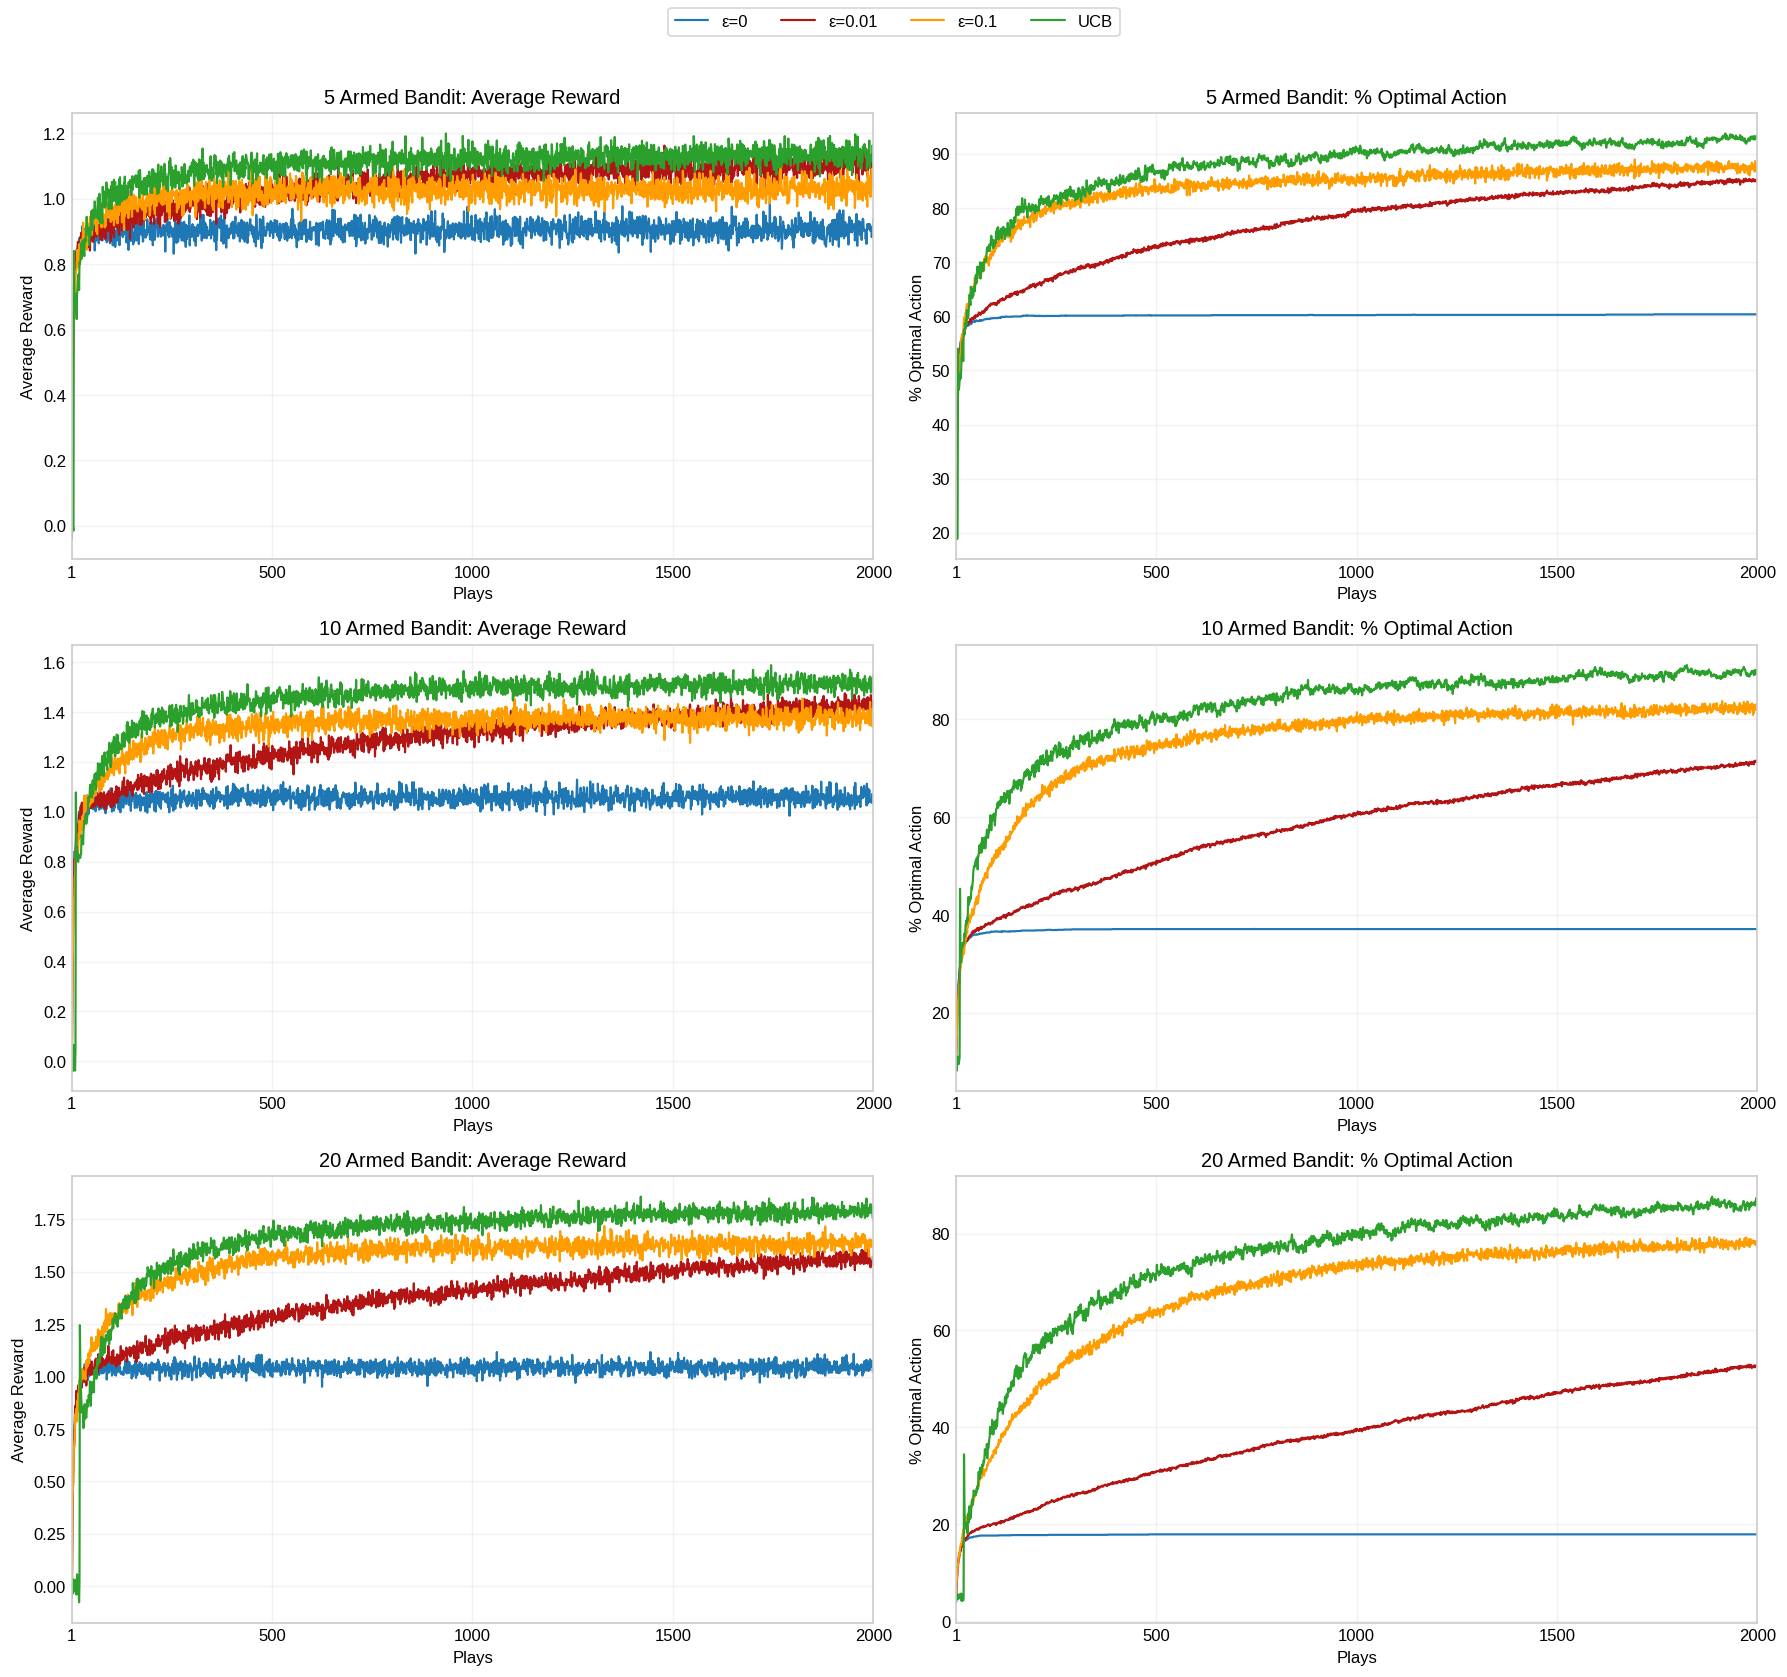

In [ ]:
# Experiment configuration.
ks = [5, 10, 20]
epsilons = [0, 0.01, 0.1]
runs = 2000
steps = 2000

# Fixed seed supports reproducible figures and summary values.
np.random.seed(532)
results_by_k = {}

# Run simulations for each k value and store aggregated outputs.
for k in ks:
    per_step_stats, summary_stats = simulate(
        k,
        runs=runs,
        steps=steps,
        epsilons=epsilons,
        use_ucb=True,
    )
    results_by_k[k] = {
        "per_step_stats": per_step_stats,
        "summary_stats": summary_stats,
    }

# Internal strategy names are kept simple, display formatting is handled later.
strategy_order = [f"epsilon={epsilon}" for epsilon in epsilons] + ["UCB"]
plot_results_grid(results_by_k, ks, strategy_order)


## 6. Summary Table

The table below shows reward and optimal-action averaged across runs for the last 500 plays and the final play.


In [ ]:
# Single combined summary table (means only).

def format_reward(value):
    """Format reward means."""
    return f"{value:.4f}"


def format_percent(value):
    """Format percentage means."""
    return f"{value:.2f}"


# Display epsilon with the Greek symbol in the printed table.
strategy_display = {name: name.replace("epsilon=", "ε=") for name in strategy_order}

print("Combined Summary (Mean Across Runs)")
header = (
    f"{'Arms (k)':>8} | {'Strategy':>10} | {'Mean Reward (Last 500 Plays)':>30} | "
    f"{'Mean Reward (Final Play)':>24} | {'Mean Optimal % (Last 500 Plays)':>32} | "
    f"{'Mean Optimal % (Final Play)':>28}"
)
print(header)
print('-' * len(header))

for k in ks:
    for strategy in strategy_order:
        stats = results_by_k[k]["summary_stats"][strategy]

        reward_last500 = format_reward(stats["reward_last500_mean"])
        reward_final = format_reward(stats["reward_final_mean"])
        optimal_last500 = format_percent(stats["optimal_last500_mean"])
        optimal_final = format_percent(stats["optimal_final_mean"])

        print(
            f"{k:8d} | {strategy_display[strategy]:10} | {reward_last500:30} | "
            f"{reward_final:24} | {optimal_last500:32} | {optimal_final:28}"
        )


Combined Summary (Mean Across Runs)
Arms (k) |   Strategy |   Mean Reward (Last 500 Plays) | Mean Reward (Final Play) |  Mean Optimal % (Last 500 Plays) |  Mean Optimal % (Final Play)
---------------------------------------------------------------------------------------------------------------------------------------------------
       5 | ε=0        | 0.9061                         | 0.9387                   | 60.31                            | 60.35                       
       5 | ε=0.01     | 1.0975                         | 1.0749                   | 84.00                            | 85.40                       
       5 | ε=0.1      | 1.0308                         | 1.0429                   | 87.17                            | 87.75                       
       5 | UCB        | 1.1325                         | 1.1030                   | 92.20                            | 92.95                       
      10 | ε=0        | 1.0577                         | 1.0602             